<a href="https://colab.research.google.com/github/zogydinesh/ITA-0616/blob/main/program18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rows: 150  Classes: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'] 

PART A: Perceptron for Setosa vs Versicolor
Mistakes in each epoch: [9, 0]
Learned weights: [0.27, 0.78, -1.04, -0.38]  bias: 0.10
Test accuracy (Setosa vs Versicolor): 100.00%

PART B: Perceptron for all 3 Iris species (One-vs-Rest)
Train size: 120  Test size: 30

Confusion Matrix (rows = actual, columns = predicted):
                 Iris-setosa  Iris-versicolor  Iris-virginica
Iris-setosa                6                1               0
Iris-versicolor            0               11               0
Iris-virginica             0                1              11

Train accuracy: 95.83%
Test accuracy:  93.33%

New flower: [5.9, 3.0, 5.1, 1.8]
Predicted species: Iris-virginica


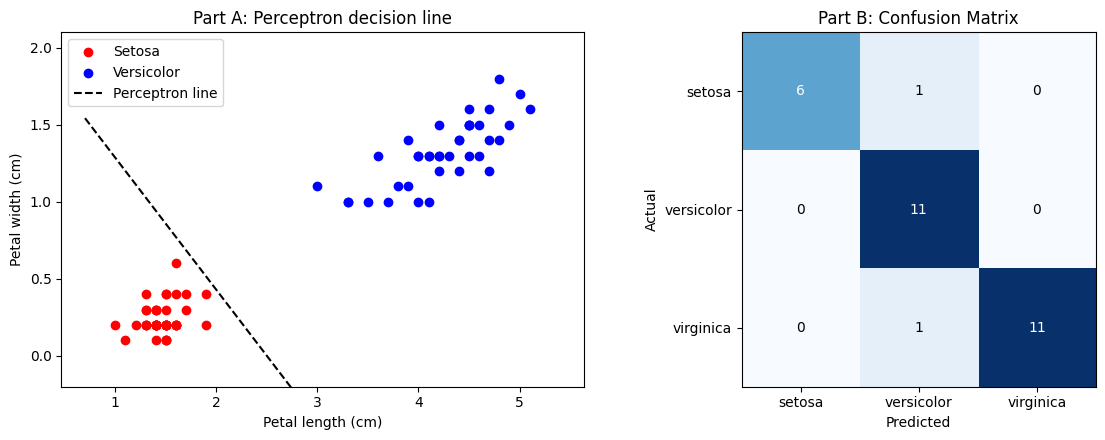

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset: Iris - UCI Machine Learning Repository (program18.csv, used as it is, no header row)

# ---- 1. Load CSV ----
cols = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
df = pd.read_csv('program18.csv', header=None, names=cols)
X = df.iloc[:, :-1].values.astype(float)
species = df['species'].values
classes = sorted(set(species))
print("Rows:", len(df), " Classes:", classes, "\n")

# ---- 2. Perceptron class ----
class Perceptron:
    def __init__(self, lr=0.1, epochs=100):
        self.lr, self.epochs = lr, epochs

    def fit(self, X, t):                       # t must be +1 or -1
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        self.errors = []
        for _ in range(self.epochs):
            mistakes = 0
            for xi, ti in zip(X, t):
                if ti * (xi @ self.w + self.b) <= 0:      # wrong prediction
                    self.w += self.lr * ti * xi           # perceptron learning rule
                    self.b += self.lr * ti
                    mistakes += 1
            self.errors.append(mistakes)
            if mistakes == 0:                  # all points correct -> stop
                break
        return self

    def score(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        return np.where(self.score(X) > 0, 1, -1)

# ================= PART A: Setosa vs Versicolor (2 classes) =================
print("PART A: Perceptron for Setosa vs Versicolor")
mask = species != 'Iris-virginica'
Xa = X[mask]
ta = np.where(species[mask] == 'Iris-setosa', 1, -1)

np.random.seed(42)
idx = np.random.permutation(len(Xa))
split = int(0.8 * len(Xa))
Xa_tr, Xa_te = Xa[idx[:split]], Xa[idx[split:]]
ta_tr, ta_te = ta[idx[:split]], ta[idx[split:]]

p = Perceptron(lr=0.1, epochs=100).fit(Xa_tr, ta_tr)
print("Mistakes in each epoch:", p.errors)
print(f"Learned weights: {np.round(p.w, 3).tolist()}  bias: {p.b:.2f}")
acc_a = np.mean(p.predict(Xa_te) == ta_te) * 100
print(f"Test accuracy (Setosa vs Versicolor): {acc_a:.2f}%\n")

# ================= PART B: all 3 species (One-vs-Rest) =================
print("PART B: Perceptron for all 3 Iris species (One-vs-Rest)")
np.random.seed(42)
idx = np.random.permutation(len(X))
split = int(0.8 * len(X))
Xtr, Xte = X[idx[:split]], X[idx[split:]]
ytr, yte = species[idx[:split]], species[idx[split:]]

mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0)             # standardize using training data
Xtr_s, Xte_s = (Xtr - mu) / sd, (Xte - mu) / sd
print("Train size:", len(Xtr), " Test size:", len(Xte))

# one perceptron per species: "this species" (+1) against "the rest" (-1)
nets = {}
for c in classes:
    nets[c] = Perceptron(lr=0.1, epochs=100).fit(Xtr_s, np.where(ytr == c, 1, -1))

def predict(Xs):
    scores = np.column_stack([nets[c].score(Xs) for c in classes])
    return np.array(classes)[scores.argmax(axis=1)]     # species with the highest score

pred = predict(Xte_s)

# ---- Confusion matrix ----
n = len(classes)
cm = np.zeros((n, n), dtype=int)
for a, q in zip(yte, pred):
    cm[classes.index(a), classes.index(q)] += 1

print("\nConfusion Matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(cm, index=classes, columns=classes))
print(f"\nTrain accuracy: {np.mean(predict(Xtr_s) == ytr) * 100:.2f}%")
print(f"Test accuracy:  {np.trace(cm) / cm.sum() * 100:.2f}%")

# ---- Classify a new flower ----
new = np.array([[5.9, 3.0, 5.1, 1.8]])
print("\nNew flower:", new[0].tolist())
print("Predicted species:", predict((new - mu) / sd)[0])

# ---- Plots ----
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# left: Part A decision line on petal length and petal width
pl = Perceptron(lr=0.1, epochs=100).fit(Xa_tr[:, 2:4], ta_tr)
for t, color, name in [(1, 'red', 'Setosa'), (-1, 'blue', 'Versicolor')]:
    pts = Xa_tr[ta_tr == t]
    ax[0].scatter(pts[:, 2], pts[:, 3], color=color, label=name)

xs = np.linspace(Xa[:, 2].min() - 0.3, Xa[:, 2].max() + 0.3, 50)
ax[0].plot(xs, -(pl.w[0] * xs + pl.b) / pl.w[1], 'k--', label='Perceptron line')
ax[0].set_ylim(Xa[:, 3].min() - 0.3, Xa[:, 3].max() + 0.3)
ax[0].set_xlabel('Petal length (cm)')
ax[0].set_ylabel('Petal width (cm)')
ax[0].set_title('Part A: Perceptron decision line')
ax[0].legend()

# right: Part B confusion matrix
ax[1].imshow(cm, cmap='Blues')
short = [c.replace('Iris-', '') for c in classes]
ax[1].set_xticks(range(n))
ax[1].set_xticklabels(short)
ax[1].set_yticks(range(n))
ax[1].set_yticklabels(short)
ax[1].set_xlabel('Predicted')
ax[1].set_ylabel('Actual')
ax[1].set_title('Part B: Confusion Matrix')

for i in range(n):
    for j in range(n):
        ax[1].text(j, i, cm[i, j], ha='center', va='center',
                   color='white' if cm[i, j] > cm.max() / 2 else 'black')

plt.tight_layout()
plt.show()